# Pairing and clock model
Pairs the head, left and right clips and builds a clock model for each device.

## Setup
This cell loads the config, the reports and the interim files, then prints the keys it found and the counts per device.

In [1]:
import json
import re
import subprocess
import zipfile
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import yaml
import av
import cv2
from tqdm import tqdm

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 50)

FPS = 30
FRAME_US = 1e6 / FPS
DEVICES = ["head", "left", "right"]

# facts from the earlier steps, only used to compare with what is measured
EXPECTED = {
    "clips_per_device": 15,
    "clip_range": {"head": (36, 50), "left": (20, 34), "right": (26, 40)},
    "full_ranks": 14,
    "full_rank_rows": 5400,
    "short_rank_rows": {"head": 1771, "left": 654, "right": 1282},
    "frame_tol_ms": 33.3,
    "rate_tol_ppm": 100,
    "rate_diff_ppm": 50,
    "left_problem_clip": 20,
    "left_control_clip": 21,
    "left_packets": 5400,
    "left_decoded": 5362,
    "black_mean": 16,
    "black_std": 8,
    "root_file": "video_20261011_200844.mp4",
    "root_creation_time": "2026-10-11T15:22:26Z",
    "root_rotation": -90,
    "filename_tz_hours": 5.5,
    "time_tol_s": 2,
}

PROJECT_ROOT = Path.cwd().resolve().parent
RAW = PROJECT_ROOT / "raw"
INTERIM = PROJECT_ROOT / "interim"
REPORTS = PROJECT_ROOT / "reports"
CONFIG_PATH = PROJECT_ROOT / "configs" / "config.yaml"

if not CONFIG_PATH.exists():
    raise RuntimeError(
        "configs\\config.yaml was not found in " + str(PROJECT_ROOT)
        + ". Start the notebook from <PROJECT_ROOT>\\notebooks so the working directory is right."
    )
REPORTS.mkdir(exist_ok=True)

with open(CONFIG_PATH, encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
print("project root:", PROJECT_ROOT)
print("config keys:", list(cfg.keys()) if isinstance(cfg, dict) else type(cfg).__name__)


def out_path(name):
    # all outputs go to reports, never into raw
    p = (REPORTS / name).resolve()
    if RAW.resolve() in p.parents:
        raise RuntimeError("refusing to write inside raw")
    return p


def load_csv(name):
    p = REPORTS / name
    if not p.exists():
        print("missing:", name)
        return None
    return pd.read_csv(p, dtype={"base_name": str, "rel_path": str, "device": str,
                                 "serial": str, "dup_suffix": str, "kind": str, "sha256": str})


manifest = load_csv("raw_manifest.csv")
imu_sum = load_csv("02_imu_file_summary.csv")
video_vs_imu = load_csv("03_video_vs_imu.csv")
packet_timing = load_csv("03_packet_timing.csv")
frame_checks = load_csv("03_frame_checks.csv")
sum03 = None
p03 = REPORTS / "03_summary.json"
if p03.exists():
    sum03 = json.loads(p03.read_text(encoding="utf-8"))
else:
    print("missing: 03_summary.json")
for nm, df in [("raw_manifest", manifest), ("02_imu_file_summary", imu_sum), ("03_video_vs_imu", video_vs_imu),
               ("03_packet_timing", packet_timing), ("03_frame_checks", frame_checks)]:
    if df is not None:
        print(f"{nm}: {len(df)} rows, columns {list(df.columns)[:12]}")
if imu_sum is None:
    raise RuntimeError("reports\\02_imu_file_summary.csv is needed and was not found")

# usable clips per device (stubs out), sorted by clip number
imu_sum["device"] = imu_sum["device"].astype(str).str.lower()
imu_sum["status"] = imu_sum["status"].astype(str).str.lower()
print("status counts:", imu_sum["status"].value_counts().to_dict())
used = imu_sum[imu_sum["status"] != "stub"].copy()
used["clip_no"] = used["clip_no"].astype(int)
clips = {}
for d in DEVICES:
    clips[d] = used[used["device"] == d].sort_values(["clip_no", "base_name"]).reset_index(drop=True)

# video paths from the manifest, with the usual folder as fallback
VIDEO_PATH = {}
if manifest is not None and {"rel_path", "device"}.issubset(manifest.columns):
    for dev, rel in zip(manifest["device"].astype(str).str.lower(), manifest["rel_path"].astype(str)):
        pp = Path(rel.replace("\\", "/"))
        if pp.suffix.lower() == ".mp4":
            VIDEO_PATH[(dev, pp.stem)] = RAW / pp


def vpath(dev, base):
    return VIDEO_PATH.get((dev, base), RAW / dev / "VIDEO_CONVERTED" / (base + ".mp4"))


def interim_path(kind, base):
    return INTERIM / kind / (base + ".npz")


def find_key(keys, words, avoid=(), prefer=""):
    cands = [k for k in keys if any(w in k.lower() for w in words) and not any(a in k.lower() for a in avoid)]
    cands.sort(key=lambda k: (prefer not in k.lower(), len(k)))
    return cands[0] if cands else None


def to_index(p, ref):
    # frame index from pts, using the packet pts of the same clip as the grid
    p = np.asarray(p, float)
    ref = np.sort(np.asarray(ref, float))
    step = float(np.median(np.diff(ref))) if len(ref) > 1 else 1.0
    pf = np.sort(p)
    stepf = float(np.median(np.diff(pf))) if len(pf) > 1 else step
    if step > 0 and abs(stepf / step - 1) < 0.05:
        return np.rint((p - ref[0]) / step).astype(int)
    return np.rint((p - pf[0]) / stepf).astype(int)


def runs_of(a):
    # runs of consecutive integers as (start, length)
    a = np.asarray(a, int)
    if len(a) == 0:
        return []
    br = np.where(np.diff(a) != 1)[0]
    starts = np.r_[a[0], a[br + 1]]
    ends = np.r_[a[br], a[-1]]
    return list(zip(starts.tolist(), (ends - starts + 1).tolist()))


# keys of the first interim file of each kind
first = {}
for kind in ["imu", "pts", "frames"]:
    for d in DEVICES:
        done = False
        for b in clips[d]["base_name"]:
            if interim_path(kind, b).exists():
                first[kind] = b
                done = True
                break
        if done:
            break
keys = {}
for kind, b in first.items():
    info = {}
    with np.load(interim_path(kind, b)) as z:
        for k in z.files:
            try:
                a = z[k]
                info[k] = (tuple(a.shape), str(a.dtype))
            except Exception:
                info[k] = ("unreadable", "")
    keys[kind] = info
    print(kind, "keys of", b + ":", info)
if set(keys) != {"imu", "pts", "frames"}:
    raise RuntimeError("could not find interim imu, pts and frames files, found: " + str(list(keys)))

fkeys = list(keys["frames"].keys())
FR_MEAN = find_key(fkeys, ["mean", "avg"], avoid=["digest"], prefer="luma")
FR_STD = find_key(fkeys, ["std"], avoid=["digest"], prefer="luma")
FR_PTS = find_key(fkeys, ["pts"], avoid=["dts", "digest"])
if None in (FR_MEAN, FR_STD, FR_PTS):
    raise RuntimeError("could not find mean luma, std luma and pts in the frames files, keys are " + str(fkeys))
print("frames keys used: mean", FR_MEAN, "| std", FR_STD, "| pts", FR_PTS)

pkeys = list(keys["pts"].keys())
PK_PTS = find_key(pkeys, ["pts"], avoid=["dts", "digest"])
if PK_PTS is None:
    cand = [k for k, (shape, dt_) in keys["pts"].items() if shape != "unreadable" and len(shape) == 1 and dt_ != "object"]
    PK_PTS = cand[0] if cand else None
    print("no key with pts in the packet files, using", PK_PTS)
print("packet pts key used:", PK_PTS)
if PK_PTS is None:
    raise RuntimeError("could not find packet timestamps in the pts files, keys are " + str(pkeys))

# load everything for the used clips
T, PTS, FR = {}, {}, {}
problems = []
todo = [(d, b) for d in DEVICES for b in clips[d]["base_name"]]
for d, b in tqdm(todo, desc="interim files"):
    try:
        with np.load(interim_path("imu", b)) as z:
            T[b] = np.asarray(z["t_us"]).astype(np.int64)
        with np.load(interim_path("pts", b)) as z:
            pp = np.asarray(z[PK_PTS], dtype=float).ravel()
            PTS[b] = pp[np.isfinite(pp)]
        with np.load(interim_path("frames", b)) as z:
            FR[b] = {"mean": np.asarray(z[FR_MEAN], dtype=float).ravel(),
                     "std": np.asarray(z[FR_STD], dtype=float).ravel(),
                     "pts": np.asarray(z[FR_PTS], dtype=float).ravel()}
    except Exception as e:
        problems.append((d, b, type(e).__name__, str(e)[:80]))
if problems:
    print("problems loading interim files:", problems[:10])

rows = []
for d in DEVICES:
    bs = list(clips[d]["base_name"])
    n_bad = sum(1 for b, r in zip(bs, clips[d]["rows"]) if b in T and len(T[b]) != int(r))
    rows.append({"device": d, "usable_clips": len(bs),
                 "stubs_excluded": int(((imu_sum["device"] == d) & (imu_sum["status"] == "stub")).sum()),
                 "imu_loaded": sum(b in T for b in bs), "pts_loaded": sum(b in PTS for b in bs),
                 "frames_loaded": sum(b in FR for b in bs), "rows_differ_from_02": n_bad})
print(pd.DataFrame(rows).to_string(index=False))

project root: C:\workstation\3RD YEAR\ego_pipeline
config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
raw_manifest: 94 rows, columns ['rel_path', 'device', 'serial', 'clip_no', 'dup_suffix', 'kind', 'size_bytes', 'sha256', 'src_modified_utc', 'src_created_utc', 'copy_verified', 'read_only']
02_imu_file_summary: 47 rows, columns ['device', 'clip_no', 'base_name', 'rows', 'status', 'first_t_us', 'last_t_us', 'span_s', 'duration_s', 'mean_rate_hz', 'dt_min_ms', 'dt_median_ms']
03_video_vs_imu: 45 rows, columns ['device', 'clip_no', 'chunk_rank', 'video_frames_packets', 'video_frames_decoded', 'imu_rows', 'frame_diff', 'video_duration_s', 'imu_duration_s', 'duration_diff_s', 'first_pts']
03_packet_timing: 47 rows, columns ['base', 'device', 'clip_no', 'dup_suffix', 'n_packets', 'first_pts', 'last_pts', 'first_dts', 'start_offset', 'duration_from_pts', 'mean_fps', 'step_min_ms']
03_frame_checks: 45 rows, column

interim files: 100%|██████████| 45/45 [00:03<00:00, 12.94it/s]

device  usable_clips  stubs_excluded  imu_loaded  pts_loaded  frames_loaded  rows_differ_from_02
  head            15               1          15          15             15                    0
  left            15               0          15          15             15                    0
 right            15               1          15          15             15                    0


## Pairing table
Clips are paired by rank inside each device. This cell builds the table and checks that the match is one to one and that the frame counts agree.

In [2]:
try:
    nrank = min(len(clips[d]) for d in DEVICES)
    rows = []
    for r in range(1, nrank + 1):
        row = {"rank": r}
        for d in DEVICES:
            c = clips[d].iloc[r - 1]
            b = c["base_name"]
            row[d + "_clip"] = int(c["clip_no"])
            row[d + "_base"] = b
            row[d + "_rows"] = len(T[b])
            row[d + "_packets"] = len(PTS[b])
            row[d + "_decoded"] = len(FR[b]["pts"])
            row[d + "_first_t_us"] = int(T[b][0])
        rows.append(row)
    pairing = pd.DataFrame(rows)
    pairing.to_csv(out_path("04_pairing.csv"), index=False)

    one_to_one = all(pairing[d + "_base"].is_unique for d in DEVICES) and all(len(clips[d]) == nrank for d in DEVICES)
    consecutive = all(bool((pairing[d + "_clip"].diff().dropna() == 1).all()) for d in DEVICES)
    range_ok = all((int(pairing[d + "_clip"].min()), int(pairing[d + "_clip"].max())) == tuple(EXPECTED["clip_range"][d])
                   for d in DEVICES)
    full = pairing[pairing["rank"] <= EXPECTED["full_ranks"]]
    pk_same = ((full["head_packets"] == full["left_packets"]) & (full["left_packets"] == full["right_packets"])).to_numpy()
    rows_eq_pk = np.all([(full[d + "_rows"] == full[d + "_packets"]).to_numpy() for d in DEVICES], axis=0)
    full_rows_ok = np.all([(full[d + "_rows"] == EXPECTED["full_rank_rows"]).to_numpy() for d in DEVICES], axis=0)
    frames_ok = pk_same & rows_eq_pk
    dec_diff = [(d, int(r["rank"])) for _, r in pairing.iterrows() for d in DEVICES if r[d + "_decoded"] != r[d + "_packets"]]
    PAIR_CHECK = {"n_triplets": nrank, "one_to_one": bool(one_to_one), "consecutive": bool(consecutive),
                  "range_ok": bool(range_ok), "frames_ok_ranks": int(frames_ok.sum()), "frames_ranks": int(len(full)),
                  "rows_are_expected": bool(full_rows_ok.all()), "decoded_differs": dec_diff}

    print("triplets:", nrank, "| one to one:", one_to_one, "| clip numbers consecutive:", consecutive, "| ranges as expected:", range_ok)
    print(f"ranks 1 to {EXPECTED['full_ranks']}: packets equal across devices and equal to imu rows in {int(frames_ok.sum())} of {len(full)}")
    print("ranks with rows not equal to 5400:", [int(x) for x in full["rank"][~full_rows_ok]])
    print("clips where decoded frames differ from packets (device, rank):", dec_diff)
    last = pairing.iloc[-1]
    print("last rank imu rows:", {d: int(last[d + "_rows"]) for d in DEVICES}, "expected", EXPECTED["short_rank_rows"])

    print(pairing[["rank", "head_base", "left_base", "right_base"]].to_string(index=False))
    cols = ["rank"] + [d + "_rows" for d in DEVICES] + [d + "_packets" for d in DEVICES] + [d + "_first_t_us" for d in DEVICES]
    print(pairing[cols].to_string(index=False))
except Exception as e:
    print("step failed:", type(e).__name__, e)

triplets: 15 | one to one: True | clip numbers consecutive: True | ranges as expected: True
ranks 1 to 14: packets equal across devices and equal to imu rows in 14 of 14
ranks with rows not equal to 5400: []
clips where decoded frames differ from packets (device, rank): [('left', 1)]
last rank imu rows: {'head': 1771, 'left': 654, 'right': 1282} expected {'head': 1771, 'left': 654, 'right': 1282}
 rank     head_base     left_base    right_base
    1 a45140-H-0036 a60617-H-0020 a59879-H-0026
    2 a45140-H-0037 a60617-H-0021 a59879-H-0027
    3 a45140-H-0038 a60617-H-0022 a59879-H-0028
    4 a45140-H-0039 a60617-H-0023 a59879-H-0029
    5 a45140-H-0040 a60617-H-0024 a59879-H-0030
    6 a45140-H-0041 a60617-H-0025 a59879-H-0031
    7 a45140-H-0042 a60617-H-0026 a59879-H-0032
    8 a45140-H-0043 a60617-H-0027 a59879-H-0033
    9 a45140-H-0044 a60617-H-0028 a59879-H-0034
   10 a45140-H-0045 a60617-H-0029 a59879-H-0035
   11 a45140-H-0046 a60617-H-0030 a59879-H-0036
   12 a45140-H-0047 a606

## Clock model per chunk
For each imu file the offset is the median of t_us minus i times 33333 us. The uncertainty comes from the MAD, and a free line fit gives the rate.

In [3]:
try:
    chunk_rows = []
    for d in DEVICES:
        for r in range(1, nrank + 1):
            b = clips[d].iloc[r - 1]["base_name"]
            t = T[b]
            n = len(t)
            i = np.arange(n)
            t0 = int(t[0])
            y = (t - t0).astype(float)
            dres = y - i * FRAME_US
            med = float(np.median(dres))
            mad = float(np.median(np.abs(dres - med)))
            unc = 1.4826 * mad / np.sqrt(n)
            sd = float(np.std(dres - med, ddof=1)) if n > 1 else float("nan")
            if n > 1:
                slope, icpt = np.polyfit(i, y, 1)
            else:
                slope, icpt = float("nan"), float("nan")
            chunk_rows.append({"device": d, "rank": r, "base": b, "n_rows": n, "first_t_us": t0,
                               "offset_us": t0 + med, "off_rel_us": med, "mad_us": mad, "unc_us": unc,
                               "resid_std_us": sd, "fit_us_per_row": float(slope),
                               "fit_rows_per_s": 1e6 / float(slope), "fit_intercept_us": float(icpt)})
    chunk_fit = pd.DataFrame(chunk_rows)
    CF = {(x["device"], x["rank"]): x for x in chunk_rows}
    out = chunk_fit.rename(columns={"off_rel_us": "offset_minus_first_us"})
    out.to_csv(out_path("04_chunk_clock_fit.csv"), index=False)
    cols = ["device", "rank", "n_rows", "offset_minus_first_us", "unc_us", "resid_std_us", "fit_rows_per_s"]
    print(out[cols].round({"offset_minus_first_us": 1, "unc_us": 2, "resid_std_us": 1, "fit_rows_per_s": 4}).to_string(index=False))
except Exception as e:
    print("step failed:", type(e).__name__, e)

device  rank  n_rows  offset_minus_first_us  unc_us  resid_std_us  fit_rows_per_s
  head     1    5400                 9987.5  344.55       20043.2         29.9924
  head     2    5400                 -812.8  151.59        9397.3         30.0002
  head     3    5400                20608.2  171.04       10090.5         30.0001
  head     4    5400                -4238.8  144.89        9123.4         29.9998
  head     5    5400                10207.8  188.21       10400.8         29.9998
  head     6    5400                -6291.2  140.99        9034.3         29.9998
  head     7    5400                 6497.3  196.89       10472.1         29.9996
  head     8    5400                -9914.7  142.86        9094.2         29.9997
  head     9    5400                 6138.2  177.32       10296.1         30.0000
  head    10    5400                -8810.5  148.05        9235.7         30.0001
  head    11    5400                  298.5  161.38        9821.6         30.0004
  head    12    

## Triplet offsets
Left minus head and right minus head offsets for every rank, flagged when they are larger than one frame. A straight line is fitted through each offset against rank.

In [4]:
try:
    rows = []
    for r in range(1, nrank + 1):
        row = {"rank": r}
        h = CF[("head", r)]
        for d in ["left", "right"]:
            x = CF[(d, r)]
            diff_us = (x["first_t_us"] - h["first_t_us"]) + (x["off_rel_us"] - h["off_rel_us"])
            row[d + "_minus_head_ms"] = diff_us / 1000
            row[d + "_unc_ms"] = float(np.hypot(x["unc_us"], h["unc_us"])) / 1000
            row[d + "_over_frame"] = bool(abs(diff_us) / 1000 > EXPECTED["frame_tol_ms"])
        rows.append(row)
    triplet = pd.DataFrame(rows)
    triplet.to_csv(out_path("04_triplet_clock_offsets.csv"), index=False)
    print(triplet.round(3).to_string(index=False))
    flagged = triplet[triplet["left_over_frame"] | triplet["right_over_frame"]]["rank"].tolist()
    print("ranks with an offset above one frame:", flagged if flagged else "none")


    def line_fit(x, y):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        slope, icpt = np.polyfit(x, y, 1)
        res = y - (icpt + slope * x)
        sxx = ((x - x.mean()) ** 2).sum()
        se = np.sqrt((res ** 2).sum() / (len(x) - 2) / sxx)
        return float(slope), float(se)


    triplet_fits = []
    for d in ["left", "right"]:
        for r0 in (1, 2):
            sub = triplet[triplet["rank"] >= r0]
            slope, se = line_fit(sub["rank"], sub[d + "_minus_head_ms"])
            triplet_fits.append({"pair": d + " minus head", "ranks": f"{r0} to {nrank}",
                                 "slope_ms_per_chunk": slope,
                                 "slope_ppm": slope / 180000.0 * 1e6, "slope_se_ppm": se / 180000.0 * 1e6,
                                 "change_13_chunks_ms": slope * 13, "change_13_se_ms": se * 13})
    print(pd.DataFrame(triplet_fits).round(3).to_string(index=False))
except Exception as e:
    print("step failed:", type(e).__name__, e)

 rank  left_minus_head_ms  left_unc_ms  left_over_frame  right_minus_head_ms  right_unc_ms  right_over_frame
    1             -53.805        0.377             True              -53.200         0.376              True
    2             -66.312        0.217             True              -65.565         0.217              True
    3             -65.212        0.237             True              -64.585         0.236              True
    4             -59.314        0.342             True              -65.952         0.206              True
    5             -31.819        0.260            False              -31.704         0.260             False
    6             -32.838        0.201            False              -32.292         0.201             False
    7             -31.365        0.276            False              -30.931         0.277             False
    8             -32.791        0.200            False              -32.032         0.202             False
    9             -

## Whole-session clock fit
One line t_us = a + b*n is fitted per device over all used rows, with n counted from the first row of rank 1.

In [5]:
try:
    N_FULL = EXPECTED["full_rank_rows"]
    BIN = 10 * FPS
    SESS = {}
    for d in DEVICES:
        bases = list(clips[d]["base_name"])
        t_ref = int(T[bases[0]][0])
        ns, ys = [], []
        for r, b in enumerate(bases):
            ns.append(r * N_FULL + np.arange(len(T[b])))
            ys.append((T[b] - t_ref).astype(float))
        n = np.concatenate(ns).astype(float)
        y = np.concatenate(ys)
        slope, icpt = np.polyfit(n, y, 1)
        res = y - (icpt + slope * n)
        rate = 1e6 / slope
        med = pd.Series(res).groupby((n // BIN).astype(int)).median()
        bins = pd.DataFrame({"minute": (med.index.to_numpy() * 10 + 5) / 60.0, "median_resid_us": med.to_numpy()})
        SESS[d] = {"t_ref_us": t_ref, "n_rows": int(len(n)), "n_last": int(n.max()) + 1, "intercept_us": float(icpt),
                   "b_us_per_row": float(slope), "rate_hz": float(rate),
                   "rate_ppm_from_30": float((rate - 30.0) / 30.0 * 1e6),
                   "resid_std_us": float(res.std(ddof=1)), "resid_max_abs_us": float(np.abs(res).max()), "bins": bins}

    n_common = min(SESS[d]["n_last"] for d in DEVICES)


    def rate_diff_ppm(x, y):
        # rate of x relative to rate of y
        return (SESS[y]["b_us_per_row"] / SESS[x]["b_us_per_row"] - 1) * 1e6


    def acc_ms(x, y):
        # elapsed time of x minus y after n_common rows
        return (SESS[x]["b_us_per_row"] - SESS[y]["b_us_per_row"]) * n_common / 1000


    SESS_DIFF = {}
    for x, y in [("left", "head"), ("right", "head"), ("right", "left")]:
        SESS_DIFF[x + "_vs_" + y] = {"rate_diff_ppm": float(rate_diff_ppm(x, y)), "accumulated_ms": float(acc_ms(x, y))}

    table = pd.DataFrame([{k: v for k, v in SESS[d].items() if k != "bins"} | {"device": d} for d in DEVICES])
    table["rate_diff_vs_head_ppm"] = [0.0 if d == "head" else SESS_DIFF[d + "_vs_head"]["rate_diff_ppm"] for d in DEVICES]
    table["accumulated_vs_head_ms"] = [0.0 if d == "head" else SESS_DIFF[d + "_vs_head"]["accumulated_ms"] for d in DEVICES]
    table = table[["device", "n_rows", "t_ref_us", "intercept_us", "b_us_per_row", "rate_hz", "rate_ppm_from_30",
                   "resid_std_us", "resid_max_abs_us", "rate_diff_vs_head_ppm", "accumulated_vs_head_ms"]]
    table.to_csv(out_path("04_session_clock_fit.csv"), index=False)
    print(table[["device", "b_us_per_row", "rate_hz", "rate_ppm_from_30", "resid_std_us", "resid_max_abs_us"]].round(
        {"b_us_per_row": 5, "rate_hz": 6, "rate_ppm_from_30": 2, "resid_std_us": 1, "resid_max_abs_us": 1}).to_string(index=False))
    for k, v in SESS_DIFF.items():
        print(f"{k}: rate difference {v['rate_diff_ppm']:.2f} ppm, accumulated {v['accumulated_ms']:.2f} ms over {n_common} rows")
except Exception as e:
    print("step failed:", type(e).__name__, e)

device  b_us_per_row   rate_hz  rate_ppm_from_30  resid_std_us  resid_max_abs_us
  head   33333.39769 29.999942             -1.93       11163.2           99580.4
  left   33333.83354 29.999550            -15.01       13732.1           74225.8
 right   33334.43854 29.999005            -33.16       13674.1           57786.5
left_vs_head: rate difference -13.08 ppm, accumulated 33.23 ms over 76254 rows
right_vs_head: rate difference -31.22 ppm, accumulated 79.37 ms over 76254 rows
right_vs_left: rate difference -18.15 ppm, accumulated 46.13 ms over 76254 rows


## Black frames across devices
A frame counts as black when mean luma is below 16 and std luma below 8. Runs of two or more are listed and put on the session clock using the offsets from step 3.

In [6]:
try:
    session_zero = min(CF[(d, 1)]["offset_us"] for d in DEVICES)
    mean_all = np.concatenate([FR[b]["mean"] for d in DEVICES for b in clips[d]["base_name"]])
    luma_scale = 255.0 if np.nanmax(mean_all) <= 1.5 else 1.0
    print("luma scale used:", luma_scale)

    rows = []
    black_frames = {d: 0 for d in DEVICES}
    for d in DEVICES:
        for r, c in enumerate(clips[d].itertuples(), start=1):
            b = c.base_name
            fr = FR[b]
            idx = to_index(fr["pts"], PTS[b])
            ip = to_index(PTS[b], PTS[b])
            nfr = int(max(idx.max(), ip.max())) + 1
            black = (fr["mean"] * luma_scale < EXPECTED["black_mean"]) & (fr["std"] * luma_scale < EXPECTED["black_std"])
            flags = np.zeros(nfr, bool)
            ok = idx[black]
            ok = ok[(ok >= 0) & (ok < nfr)]
            flags[ok] = True
            black_frames[d] += int(flags.sum())
            dd = np.diff(np.r_[0, flags.astype(int), 0])
            starts = np.where(dd == 1)[0]
            ends = np.where(dd == -1)[0]
            off = CF[(d, r)]["offset_us"]
            for s0, e0 in zip(starts, ends):
                if e0 - s0 >= 2:
                    rows.append({"device": d, "rank": r, "clip": int(c.clip_no), "base": b, "start_frame": int(s0),
                                 "length": int(e0 - s0),
                                 "start_s": (off + s0 * FRAME_US - session_zero) / 1e6,
                                 "end_s": (off + e0 * FRAME_US - session_zero) / 1e6})
    BLACK = pd.DataFrame(rows, columns=["device", "rank", "clip", "base", "start_frame", "length", "start_s", "end_s"])
    BLACK.to_csv(out_path("04_black_runs.csv"), index=False)
    print("black frames per device:", black_frames)
    print("runs of 2 or more per device:", BLACK["device"].value_counts().reindex(DEVICES).fillna(0).astype(int).to_dict())

    parts = []
    for d in DEVICES:
        for r in (1, 2, nrank):
            parts.append(BLACK[(BLACK["device"] == d) & (BLACK["rank"] == r)])
    show = pd.concat(parts)
    if len(show) == 0:
        print("no runs in rank 1, 2 or", nrank)
    else:
        print(show[["device", "rank", "clip", "start_frame", "length", "start_s", "end_s"]].head(50).round(2).to_string(index=False))
        if len(show) > 50:
            print(f"... {len(show) - 50} more rows in the csv")

    # overlap in session time between devices
    pairs = {}
    for a, b2 in [("head", "left"), ("head", "right"), ("left", "right")]:
        A = BLACK[BLACK["device"] == a]
        B = BLACK[BLACK["device"] == b2]
        tot, cnt = 0.0, 0
        for s, e in zip(A["start_s"], A["end_s"]):
            ov = np.minimum(e, B["end_s"].to_numpy()) - np.maximum(s, B["start_s"].to_numpy())
            ov = ov[ov > 0]
            tot += float(ov.sum())
            cnt += int(len(ov))
        pairs[a + "-" + b2] = {"overlapping_runs": cnt, "overlap_s": tot}
    BLACK_OVERLAP = {"pairs": pairs, "any": any(v["overlapping_runs"] > 0 for v in pairs.values()),
                     "total_s": sum(v["overlap_s"] for v in pairs.values())}
    for k, v in pairs.items():
        print(f"{k}: {v['overlapping_runs']} overlapping run pairs, {v['overlap_s']:.2f} s together")
    print("black runs of different devices overlap in session time:", "yes" if BLACK_OVERLAP["any"] else "no")
except Exception as e:
    print("step failed:", type(e).__name__, e)

luma scale used: 1.0
black frames per device: {'head': 128, 'left': 109, 'right': 328}
runs of 2 or more per device: {'head': 2, 'left': 7, 'right': 8}
device  rank  clip  start_frame  length  start_s   end_s
  head     1    36         4817     109   160.62  164.25
  head     1    36         5373      19   179.15  179.79
  left     1    20         3809       3   126.97  127.07
  left     1    20         4862      10   162.07  162.40
  left     1    20         4889      40   162.97  164.30
  left     1    20         5375      25   179.17  180.00
  left     2    21            0      25   179.99  180.83
  left     2    21           38       3   181.26  181.36
  left    15    34          431       3  2534.39 2534.49
 right     1    26         2946       8    98.20   98.47
 right     1    26         3748       5   124.93  125.10
 right     1    26         4808     118   160.27  164.20
 right     1    26         5221      29   174.03  175.00
 right     1    26         5324       4   177.47  

## Left 0020 decoding problem
The decoded frame pts are compared with the packet pts to find the missing frames. Then ffmpeg is run on left 0020 and on left 0021 as a control, and the packets around the first gap are listed.

In [7]:
MISSING = {}
try:
    sel = clips["left"][clips["left"]["clip_no"] == EXPECTED["left_problem_clip"]]
    ctl = clips["left"][clips["left"]["clip_no"] == EXPECTED["left_control_clip"]]
    if len(sel) == 0:
        raise RuntimeError("left clip %d not found" % EXPECTED["left_problem_clip"])
    base20 = sel.iloc[0]["base_name"]
    print("left clip", EXPECTED["left_problem_clip"], "is", base20)
    ptsp = np.sort(PTS[base20])
    idx_p = to_index(ptsp, ptsp)
    idx_f = to_index(FR[base20]["pts"], PTS[base20])
    miss = np.setdiff1d(idx_p, idx_f)
    print("packets:", len(ptsp), "(expected", EXPECTED["left_packets"], ") | decoded frames:", len(idx_f), "(expected", EXPECTED["left_decoded"], ")")
    print("missing frame indices:", len(miss))
    other = [(d, b, len(PTS[b]), len(FR[b]["pts"])) for d in DEVICES for b in clips[d]["base_name"] if len(PTS[b]) != len(FR[b]["pts"])]
    print("clips with decoded count different from packets:", [(o[0], o[1], o[2], o[3]) for o in other])
    if len(miss):
        runs = runs_of(miss)
        print("first missing:", int(miss[0]), "| last missing:", int(miss[-1]), "| runs:", len(runs))
        print("runs (start, length):", runs[:20], "..." if len(runs) > 20 else "")
        run_id = np.zeros(len(miss), int)
        k = 0
        for j, (s0, ln) in enumerate(runs):
            run_id[k:k + ln] = j
            k += ln
        mp = dict(zip(idx_p.tolist(), ptsp.tolist()))
        pd.DataFrame({"frame_index": miss, "run": run_id, "time_s": miss / FPS,
                      "packet_pts": [mp.get(int(m)) for m in miss]}).to_csv(out_path("04_left0020_missing_frames.csv"), index=False)
    else:
        pd.DataFrame(columns=["frame_index", "run", "time_s", "packet_pts"]).to_csv(out_path("04_left0020_missing_frames.csv"), index=False)
        runs = []
    MISSING = {"base": base20, "packets": int(len(ptsp)), "decoded": int(len(idx_f)), "missing": int(len(miss)),
               "first": int(miss[0]) if len(miss) else None, "last": int(miss[-1]) if len(miss) else None, "runs": runs,
               "indices": [int(m) for m in miss]}
except Exception as e:
    print("step failed:", type(e).__name__, e)

left clip 20 is a60617-H-0020
packets: 5400 (expected 5400 ) | decoded frames: 5362 (expected 5362 )
missing frame indices: 38
clips with decoded count different from packets: [('left', 'a60617-H-0020', 5400, 5362)]
first missing: 2332 | last missing: 2369 | runs: 1
runs (start, length): [(2332, 38)] 


In [8]:
# ffmpeg decode messages for left 0020 and the control
try:
    def run_ffmpeg(path):
        cmd = ["ffmpeg", "-nostdin", "-v", "error", "-i", str(path), "-f", "null", "-"]
        try:
            p = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=900)
            return p.stderr.splitlines(), p.returncode
        except subprocess.TimeoutExpired:
            return ["timeout after 900 s"], None


    text = []
    msgs = {}
    for label, sub in [("left %04d" % EXPECTED["left_problem_clip"], sel), ("left %04d (control)" % EXPECTED["left_control_clip"], ctl)]:
        if len(sub) == 0:
            print("clip not found for", label)
            continue
        b = sub.iloc[0]["base_name"]
        lines, rc = run_ffmpeg(vpath("left", b))
        msgs[label] = lines
        text.append("== " + label + " | " + b + " | " + str(len(lines)) + " stderr lines | return code " + str(rc) + " ==")
        text.extend(lines[:100])
        text.append("")
        print(label + ":", len(lines), "stderr lines")
    out_path("04_decode_messages.txt").write_text("\n".join(text), encoding="utf-8")
    first_label = "left %04d" % EXPECTED["left_problem_clip"]
    print("first 10 lines of", first_label)
    for ln in msgs.get(first_label, [])[:10]:
        print("  ", ln[:150])
except Exception as e:
    print("step failed:", type(e).__name__, e)

left 0020: 85 stderr lines
left 0021 (control): 0 stderr lines
first 10 lines of left 0020
   [hevc @ 000001ff7e8250c0] Invalid NAL unit size (-659891834 > 6828).
   [hevc @ 000001ff7e8250c0] Error splitting the input into NAL units.
   [hevc @ 000001ff7e86e640] Invalid NAL unit size (657917184 > 6995).
   [hevc @ 000001ff7e86e640] Error splitting the input into NAL units.
   [hevc @ 000001ff7ef52a40] Invalid NAL unit size (67310080 > 7188).
   [hevc @ 000001ff7ef52a40] Error splitting the input into NAL units.
   [hevc @ 000001ff7ef71800] Invalid NAL unit size (0 > 7453).
   [hevc @ 000001ff7ef71800] Error splitting the input into NAL units.
   [hevc @ 000001ff7ef7dbc0] Invalid NAL unit size (0 > 7194).
   [hevc @ 000001ff7ef7dbc0] Error splitting the input into NAL units.


In [9]:
# packets around the first missing frame
try:
    if not MISSING or MISSING["first"] is None:
        print("no missing frames, nothing to list")
    else:
        pk = []
        with av.open(str(vpath("left", MISSING["base"]))) as c:
            s = c.streams.video[0]
            tb = float(s.time_base)
            for k, p in enumerate(c.demux(s)):
                if p.pts is None:
                    continue
                pk.append({"decode_order": k, "pts": p.pts, "size": p.size, "keyframe": bool(p.is_keyframe)})
        pk = pd.DataFrame(pk)
        pk["frame_index"] = np.rint((pk["pts"] - pk["pts"].min()) * tb * FPS).astype(int)
        pk = pk.sort_values("frame_index").reset_index(drop=True)
        f0 = MISSING["first"]
        win = pk[(pk["frame_index"] >= f0 - 5) & (pk["frame_index"] <= f0 + 5)].copy()
        win["missing_in_decode"] = win["frame_index"].isin(set(MISSING["indices"]))
        print("packets around first missing frame", f0, "(presentation order)")
        print(win[["frame_index", "decode_order", "size", "keyframe", "missing_in_decode"]].to_string(index=False))
        print("keyframes before the gap:", pk[(pk["keyframe"]) & (pk["frame_index"] <= f0)]["frame_index"].tail(3).tolist())
except Exception as e:
    print("step failed:", type(e).__name__, e)

packets around first missing frame 2332 (presentation order)
 frame_index  decode_order  size  keyframe  missing_in_decode
        2327          2327  7277     False              False
        2328          2328  7501     False              False
        2329          2329  7533     False              False
        2330          2330  7752     False              False
        2331          2331  7540     False              False
        2332          2332  6832     False               True
        2333          2333  6999     False               True
        2334          2334  7192     False               True
        2335          2335  7457     False               True
        2336          2336  7198     False               True
        2337          2337  7067     False               True
keyframes before the gap: [2250, 2280, 2310]


## HEVC bitstream provenance
For the first clip of each device the codec extradata and the first 3 packets are searched for printable text, and the stream tags are read with ffprobe.

In [10]:
HEVC = {"found": False, "names": [], "tag_names": []}
try:
    ascii_run = re.compile(rb"[\x20-\x7e]{6,}")
    names = ["x265", "libx265", "lavc", "libavcodec", "lavf", "ffmpeg", "x264", "mediacodec", "nvenc", "videotoolbox", "handbrake"]


    def ffprobe_tags(path):
        cmd = ["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries", "stream_tags:format_tags", "-of", "json", str(path)]
        p = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60)
        return json.loads(p.stdout) if p.stdout.strip() else {}


    lines_out = []
    bit_text = []
    tag_text = []
    for d in DEVICES:
        b = clips[d].iloc[0]["base_name"]
        vp = vpath(d, b)
        with av.open(str(vp)) as c:
            s = c.streams.video[0]
            extra = bytes(s.codec_context.extradata or b"")
            pkts = []
            for p in c.demux(s):
                if p.size == 0:
                    continue
                pkts.append(bytes(p))
                if len(pkts) == 3:
                    break
        tags = ffprobe_tags(vp)
        stream_tags = (tags.get("streams") or [{}])[0].get("tags", {})
        format_tags = tags.get("format", {}).get("tags", {})
        lines_out.append("== " + d + " | " + b + " ==")
        lines_out.append("extradata bytes: " + str(len(extra)) + " | first 3 packet sizes: " + str([len(x) for x in pkts]))
        dev_runs = []
        for label, blob in [("extradata", extra)] + [("packet %d" % (k + 1), x) for k, x in enumerate(pkts)]:
            for m in ascii_run.finditer(blob):
                dev_runs.append(m.group().decode("ascii"))
                lines_out.append(label + ": " + dev_runs[-1])
        bit_text.extend(dev_runs)
        for label, dct in [("stream tags", stream_tags), ("format tags", format_tags)]:
            lines_out.append(label + ": " + json.dumps(dct))
            tag_text.extend(str(v) for v in dct.values())
        print(d, b, "| text runs of 6 or more in extradata and first 3 packets:", len(dev_runs))
        for rr in dev_runs[:4]:
            print("   ", rr[:110])
        print("    stream tags:", {k: stream_tags.get(k) for k in ["handler_name", "vendor_id", "encoder"]},
              "| format encoder:", format_tags.get("encoder"))
    in_bits = [n for n in names if n in " ".join(bit_text).lower()]
    in_tags = [n for n in names if n in " ".join(tag_text).lower()]
    HEVC = {"found": bool(in_bits), "names": in_bits, "tag_names": in_tags}
    if in_bits:
        verdict = "an encoder name appears in the bitstream: " + ", ".join(in_bits)
    else:
        verdict = "no encoder name such as x265 or Lavc appears in the extradata or the first 3 packets"
    verdict += " | in the stream and format tags: " + (", ".join(in_tags) if in_tags else "none")
    print("result:", verdict)
    lines_out.append("")
    lines_out.append("result: " + verdict)
    out_path("04_hevc_strings.txt").write_text("\n".join(lines_out), encoding="utf-8")
except Exception as e:
    print("step failed:", type(e).__name__, e)

head a45140-H-0036 | text runs of 6 or more in extradata and first 3 packets: 88
    4]M%%I
    lZyjszl
    1]:911i
    cbt/3Yt
    stream tags: {'handler_name': 'VideoHandler', 'vendor_id': None, 'encoder': None} | format encoder: Lavf63.1.102
left a60617-H-0020 | text runs of 6 or more in extradata and first 3 packets: 73
    9x-rHFv
    xs'82S
    FRKtnK
    }xgpd]
    stream tags: {'handler_name': 'VideoHandler', 'vendor_id': None, 'encoder': None} | format encoder: Lavf63.1.102
right a59879-H-0026 | text runs of 6 or more in extradata and first 3 packets: 193
    SmF%9;EQ
    @:~Fdz
    >x)D9,*HY
    AK NKW
    stream tags: {'handler_name': 'VideoHandler', 'vendor_id': None, 'encoder': None} | format encoder: Lavf63.1.102
result: no encoder name such as x265 or Lavc appears in the extradata or the first 3 packets | in the stream and format tags: lavf


## Root video time anchor
The creation_time tag of the root video is taken as the end of the recording, so the start is creation_time minus the duration. This is compared with the time in the file name, read as IST.

In [11]:
TIME = {}
try:
    root_path = RAW / EXPECTED["root_file"]
    with av.open(str(root_path)) as c:
        vs = c.streams.video[0]
        ct_container = c.metadata.get("creation_time")
        ct_stream = vs.metadata.get("creation_time")
        dur_stream = float(vs.duration * vs.time_base) if vs.duration else None
        dur_container = c.duration / 1e6 if c.duration else None
        start_stream = float(vs.start_time * vs.time_base) if vs.start_time else 0.0
    ct_text = ct_container or ct_stream
    print("creation_time tag (container, stream):", ct_container, ",", ct_stream, "| expected", EXPECTED["root_creation_time"])
    print("duration (stream, container) s:", dur_stream, ",", dur_container)
    if sum03 and isinstance(sum03.get("root_video"), dict):
        rv = sum03["root_video"]
        print("from 03_summary:", {k: rv.get(k) for k in ["duration_pts_s", "creation_time"]})
    root_dur = dur_stream if dur_stream else dur_container
    utc = dt.timezone.utc
    ist = dt.timezone(dt.timedelta(hours=EXPECTED["filename_tz_hours"]))
    creation = dt.datetime.fromisoformat(ct_text.replace("Z", "+00:00")).astimezone(utc)
    root_start = creation - dt.timedelta(seconds=root_dur)
    m = re.search(r"(\d{8})_(\d{6})", EXPECTED["root_file"])
    fname_local = dt.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S").replace(tzinfo=ist)
    fname_utc = fname_local.astimezone(utc)
    diff_s = (root_start - fname_utc).total_seconds()
    fmt = lambda t: t.strftime("%Y-%m-%d %H:%M:%S")
    print("root start from tag (UTC):", fmt(root_start), "| IST:", fmt(root_start.astimezone(ist)))
    print("file name time as IST -> UTC:", fmt(fname_utc), "| difference tag minus name: %.2f s" % diff_s)

    dev = {}
    for d in DEVICES:
        frames = int(pairing[d + "_packets"].sum())
        length = frames / FPS
        slack = root_dur - length
        e = {"frames": frames, "length_s": length, "slack_s": slack}
        if slack >= 0:
            e["earliest_start_utc"] = root_start.isoformat()
            e["latest_start_utc"] = (root_start + dt.timedelta(seconds=slack)).isoformat()
            print(f"{d}: {frames} frames = {length:.1f} s, slack {slack:.1f} s")
            print("   start between", fmt(root_start), "and", fmt(root_start + dt.timedelta(seconds=slack)), "UTC")
            print("   start between", fmt(root_start.astimezone(ist)), "and", fmt((root_start + dt.timedelta(seconds=slack)).astimezone(ist)), "IST")
        else:
            print(f"{d}: session {length:.1f} s is longer than the root video ({root_dur:.1f} s), no window")
        dev[d] = e
    TIME = {"root_dur_s": root_dur, "root_start": root_start, "diff_s": diff_s, "dev": dev, "root_start_pts_s": start_stream}
    anchor = {"root_file": EXPECTED["root_file"], "creation_time_container": ct_container, "creation_time_stream": ct_stream,
              "duration_stream_s": dur_stream, "duration_container_s": dur_container,
              "root_start_utc": root_start.isoformat(), "root_start_ist": root_start.astimezone(ist).isoformat(),
              "file_name_time_ist": fname_local.isoformat(), "file_name_time_utc": fname_utc.isoformat(),
              "tag_minus_name_s": diff_s, "devices": dev,
              "assumptions": ["creation_time marks the end of the recording",
                              "the root video covers the whole device session",
                              "the file name time is local time in IST (UTC+05:30)",
                              "device session length is the total number of video packets divided by 30",
                              "the clips of a device follow each other without gaps"]}
    out_path("04_time_anchor.json").write_text(json.dumps(anchor, indent=2), encoding="utf-8")
except Exception as e:
    print("step failed:", type(e).__name__, e)

creation_time tag (container, stream): 2026-10-11T15:22:26.000000Z , 2026-10-11T15:22:26.000000Z | expected 2026-10-11T15:22:26Z
duration (stream, container) s: 2621.3459555555555 , 2621.345956
from 03_summary: {'duration_pts_s': 2621.3460555555557, 'creation_time': '2026-10-11T15:22:26.000000Z'}
root start from tag (UTC): 2026-10-11 14:38:44 | IST: 2026-10-11 20:08:44
file name time as IST -> UTC: 2026-10-11 14:38:44 | difference tag minus name: 0.65 s
head: 77371 frames = 2579.0 s, slack 42.3 s
   start between 2026-10-11 14:38:44 and 2026-10-11 14:39:26 UTC
   start between 2026-10-11 20:08:44 and 2026-10-11 20:09:26 IST
left: 76254 frames = 2541.8 s, slack 79.5 s
   start between 2026-10-11 14:38:44 and 2026-10-11 14:40:04 UTC
   start between 2026-10-11 20:08:44 and 2026-10-11 20:10:04 IST
right: 76882 frames = 2562.7 s, slack 58.6 s
   start between 2026-10-11 14:38:44 and 2026-10-11 14:39:43 UTC
   start between 2026-10-11 20:08:44 and 2026-10-11 20:09:43 IST


## Sync sheets
Two pictures to check the start and the end by eye. The top row is the root video, the second row is the head camera. Frames are found by seeking, not by decoding everything.

In [12]:
try:
    def probe_rotation(path):
        cmd = ["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
               "stream_side_data=rotation:stream_tags=rotate", "-of", "json", str(path)]
        p = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60)
        data = json.loads(p.stdout) if p.stdout.strip() else {}
        s = (data.get("streams") or [{}])[0]
        for sd in s.get("side_data_list", []):
            if "rotation" in sd:
                return float(sd["rotation"])
        tag = s.get("tags", {}).get("rotate")
        return -float(tag) if tag else None


    rot = probe_rotation(root_path)
    if rot is None:
        rot = EXPECTED["root_rotation"]
        print("no rotation found by ffprobe, using", rot)
    else:
        print("rotation read by ffprobe:", rot)
    cw = int(round(-rot)) % 360
    rot_code = {90: cv2.ROTATE_90_CLOCKWISE, 180: cv2.ROTATE_180, 270: cv2.ROTATE_90_COUNTERCLOCKWISE}.get(cw)


    def get_frame(container, stream, t_s):
        tb = float(stream.time_base)
        start = float(stream.start_time * tb) if stream.start_time else 0.0
        target = start + max(t_s, 0.0)
        container.seek(int(target / tb), stream=stream, backward=True, any_frame=False)
        last = None
        for k, fr in enumerate(container.decode(stream)):
            last = fr
            if fr.pts is not None and fr.pts * tb >= target - 1e-6:
                break
            if k > 3000:
                break
        return last.to_ndarray(format="rgb24") if last is not None else None


    def thumb(img, rotate=False):
        if img is None:
            return None
        if rotate and rot_code is not None:
            img = cv2.rotate(img, rot_code)
        h = int(round(img.shape[0] * 240 / img.shape[1]))
        return cv2.resize(img, (240, h), interpolation=cv2.INTER_AREA)


    def grab_many(path, times, rotate=False):
        out = []
        with av.open(str(path)) as c:
            s = c.streams.video[0]
            for t in times:
                if t is None:
                    out.append(None)
                    continue
                try:
                    out.append(thumb(get_frame(c, s, t), rotate))
                except Exception as e:
                    print("   frame at", round(t, 1), "s failed:", type(e).__name__)
                    out.append(None)
        return out


    def make_sheet(path_out, rows, title):
        # rows is a list of (images, labels)
        ncol = max(len(r[0]) for r in rows)
        heights = [max([im.shape[0] for im in r[0] if im is not None] or [135]) for r in rows]
        fig, axes = plt.subplots(len(rows), ncol, figsize=(ncol * 2.45, sum(heights) / 100 + 0.7),
                                 gridspec_kw={"height_ratios": heights}, squeeze=False)
        for ri, (imgs, labels) in enumerate(rows):
            for ci in range(ncol):
                ax = axes[ri][ci]
                ax.axis("off")
                if ci < len(imgs) and imgs[ci] is not None:
                    ax.imshow(imgs[ci])
                    ax.text(0.02, 0.98, labels[ci], transform=ax.transAxes, fontsize=6, color="white", va="top",
                            bbox=dict(facecolor="black", alpha=0.6, pad=1, lw=0))
        fig.suptitle(title, fontsize=9)
        fig.subplots_adjust(left=0.003, right=0.997, top=0.93, bottom=0.003, wspace=0.02, hspace=0.04)
        fig.savefig(out_path(path_out), dpi=100)
        plt.close(fig)


    head1 = clips["head"].iloc[0]["base_name"]
    headN = clips["head"].iloc[nrank - 1]["base_name"]
    root_dur = TIME["root_dur_s"]

    # start sheet
    ts = list(range(0, 61, 5))
    root_imgs = grab_many(root_path, [float(t) for t in ts], rotate=True)
    head_len1 = int(pairing["head_packets"].iloc[0]) / FPS
    head_imgs = grab_many(vpath("head", head1), [float(t) if t < head_len1 else None for t in ts])
    make_sheet("04_sync_sheet_start.png",
               [(root_imgs, ["root %d s" % t for t in ts]), (head_imgs, ["head rank 1, %d s" % t for t in ts])],
               "start: root video (top) and head rank 1 (bottom), same offsets from each start")
    print("saved 04_sync_sheet_start.png")

    # end sheet
    back = list(range(60, 0, -5))
    head_len = int(pairing["head_packets"].iloc[nrank - 1]) / FPS
    root_t = [max(root_dur - bk, 0.0) for bk in back]
    head_t = [head_len - bk if bk <= head_len else None for bk in back]
    root_imgs = grab_many(root_path, root_t, rotate=True)
    head_imgs = grab_many(vpath("head", headN), head_t)
    make_sheet("04_sync_sheet_end.png",
               [(root_imgs, ["root end-%d s" % bk for bk in back]), (head_imgs, ["head rank %d end-%d s" % (nrank, bk) for bk in back])],
               "end: last 60 s of the root video (top) and the end of head rank %d (bottom)" % nrank)
    print("saved 04_sync_sheet_end.png (last head clip is %.1f s long)" % head_len)
except Exception as e:
    print("step failed:", type(e).__name__, e)

rotation read by ffprobe: -90.0
saved 04_sync_sheet_start.png
saved 04_sync_sheet_end.png (last head clip is 59.0 s long)


## Hypothesis tests
Each test is computed from the numbers above. PASS and FLAG are checks, INFO is only reported.

In [13]:
try:
    rowsH = []


    def test(tid, hyp, fn):
        try:
            meas, res = fn()
        except Exception as e:
            meas, res = "not computed (" + type(e).__name__ + ")", "FLAG"
        rowsH.append({"id": tid, "hypothesis": hyp, "measured": meas, "result": res})


    def p1():
        c = PAIR_CHECK
        ok = c["one_to_one"] and c["n_triplets"] == EXPECTED["clips_per_device"] and c["range_ok"]
        return f"{c['n_triplets']} triplets, one to one {c['one_to_one']}, clip ranges as expected {c['range_ok']}", "PASS" if ok else "FLAG"


    def p2():
        c = PAIR_CHECK
        ok = c["frames_ok_ranks"] == c["frames_ranks"] and c["rows_are_expected"]
        return f"{c['frames_ok_ranks']} of {c['frames_ranks']} ranks equal; decoded differs in {len(c['decoded_differs'])} clips", "PASS" if ok else "FLAG"


    def p3():
        v = triplet[["left_minus_head_ms", "right_minus_head_ms"]].abs()
        mx = float(v.to_numpy().max())
        return f"max {mx:.2f} ms", "PASS" if mx <= EXPECTED["frame_tol_ms"] else "FLAG"


    def p4():
        ppm = {d: SESS[d]["rate_ppm_from_30"] for d in DEVICES}
        ok = all(abs(v) < EXPECTED["rate_tol_ppm"] for v in ppm.values())
        return ", ".join(f"{d} {v:.1f} ppm" for d, v in ppm.items()), "PASS" if ok else "FLAG"


    def p5():
        mx = max(abs(v["rate_diff_ppm"]) for v in SESS_DIFF.values())
        return f"max {mx:.2f} ppm", "PASS" if mx < EXPECTED["rate_diff_ppm"] else "FLAG"


    def p6():
        pr = BLACK_OVERLAP["pairs"]
        return f"{len(BLACK)} runs, overlap {BLACK_OVERLAP['total_s']:.2f} s ({', '.join(str(v['overlapping_runs']) for v in pr.values())} run pairs)", "INFO"


    def p7():
        return f"{MISSING['missing']} missing, first {MISSING['first']}, last {MISSING['last']}, {len(MISSING['runs'])} runs", "INFO"


    def p8():
        return (("bitstream: " + ", ".join(HEVC["names"])) if HEVC["found"] else "none in bitstream") + "; tags: " + (", ".join(HEVC["tag_names"]) or "none"), "INFO"


    def p9():
        d = TIME["diff_s"]
        return f"{d:.2f} s", "PASS" if abs(d) <= EXPECTED["time_tol_s"] else "FLAG"


    def p10():
        return ", ".join(f"{d} {TIME['dev'][d]['slack_s']:.1f} s" for d in DEVICES), "INFO"


    test("P1", "15 triplets pair one to one", p1)
    test("P2", "frame counts equal across devices (ranks 1 to 14) and equal to imu rows", p2)
    test("P3", "every triplet offset within 33.3 ms", p3)
    test("P4", "whole-session rate within 100 ppm of 30 Hz", p4)
    test("P5", "rate difference between devices below 50 ppm", p5)
    test("P6", "black runs overlap between devices", p6)
    test("P7", "left 0020 missing frames located", p7)
    test("P8", "encoder string in the HEVC bitstream", p8)
    test("P9", "root start from tag equals file name time (IST) within 2 s", p9)
    test("P10", "slack between root duration and device session", p10)
    hyp = pd.DataFrame(rowsH)
    hyp.to_csv(out_path("04_hypothesis_check.csv"), index=False)
    print(hyp.to_string(index=False, max_colwidth=90))
except Exception as e:
    print("step failed:", type(e).__name__, e)

 id                                                              hypothesis                                                   measured result
 P1                                             15 triplets pair one to one 15 triplets, one to one True, clip ranges as expected True   PASS
 P2 frame counts equal across devices (ranks 1 to 14) and equal to imu rows           14 of 14 ranks equal; decoded differs in 1 clips   PASS
 P3                                     every triplet offset within 33.3 ms                                               max 66.31 ms   FLAG
 P4                              whole-session rate within 100 ppm of 30 Hz             head -1.9 ppm, left -15.0 ppm, right -33.2 ppm   PASS
 P5                            rate difference between devices below 50 ppm                                              max 31.22 ppm   PASS
 P6                                      black runs overlap between devices                17 runs, overlap 9.80 s (3, 2, 7 run pairs)   INFO
 P7   

## Figures
The clock model figure has four panels. A second figure shows the black runs on the session clock.

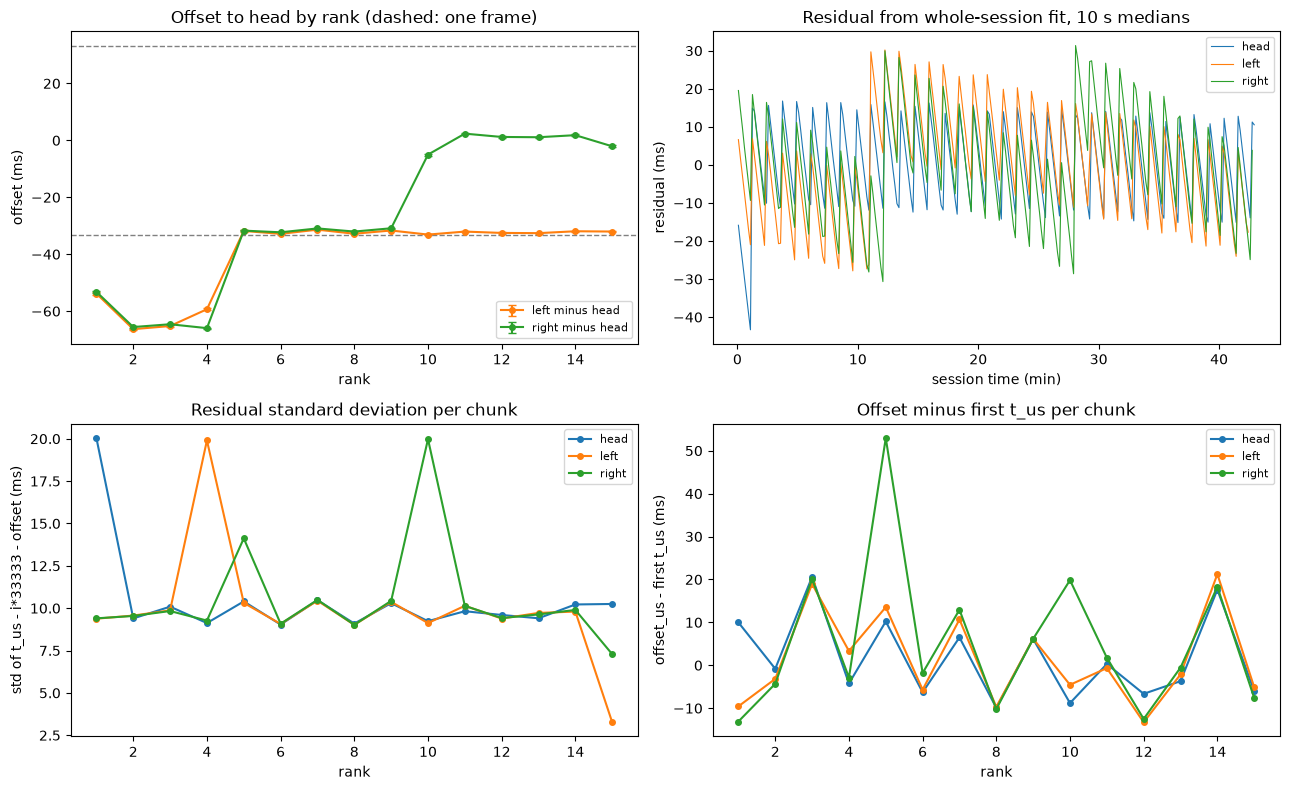

In [14]:
try:
    colors = {"head": "tab:blue", "left": "tab:orange", "right": "tab:green"}
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))

    a = ax[0][0]
    for d, col in [("left", "tab:orange"), ("right", "tab:green")]:
        a.errorbar(triplet["rank"], triplet[d + "_minus_head_ms"], yerr=triplet[d + "_unc_ms"], fmt="o-", ms=4,
                   capsize=3, color=col, label=d + " minus head")
    a.axhline(EXPECTED["frame_tol_ms"], color="grey", ls="--", lw=1)
    a.axhline(-EXPECTED["frame_tol_ms"], color="grey", ls="--", lw=1)
    a.set_title("Offset to head by rank (dashed: one frame)")
    a.set_xlabel("rank")
    a.set_ylabel("offset (ms)")
    a.legend(fontsize=8)

    a = ax[0][1]
    for d in DEVICES:
        bn = SESS[d]["bins"]
        a.plot(bn["minute"], bn["median_resid_us"] / 1000, lw=0.8, color=colors[d], label=d)
    a.set_title("Residual from whole-session fit, 10 s medians")
    a.set_xlabel("session time (min)")
    a.set_ylabel("residual (ms)")
    a.legend(fontsize=8)

    a = ax[1][0]
    for d in DEVICES:
        sub = chunk_fit[chunk_fit["device"] == d]
        a.plot(sub["rank"], sub["resid_std_us"] / 1000, "o-", ms=4, color=colors[d], label=d)
    a.set_title("Residual standard deviation per chunk")
    a.set_xlabel("rank")
    a.set_ylabel("std of t_us - i*33333 - offset (ms)")
    a.legend(fontsize=8)

    a = ax[1][1]
    for d in DEVICES:
        sub = chunk_fit[chunk_fit["device"] == d]
        a.plot(sub["rank"], sub["off_rel_us"] / 1000, "o-", ms=4, color=colors[d], label=d)
    a.set_title("Offset minus first t_us per chunk")
    a.set_xlabel("rank")
    a.set_ylabel("offset_us - first t_us (ms)")
    a.legend(fontsize=8)

    fig.tight_layout()
    fig.savefig(out_path("04_clock_model.png"), dpi=150)
    plt.show()
    plt.close(fig)
except Exception as e:
    print("step failed:", type(e).__name__, e)

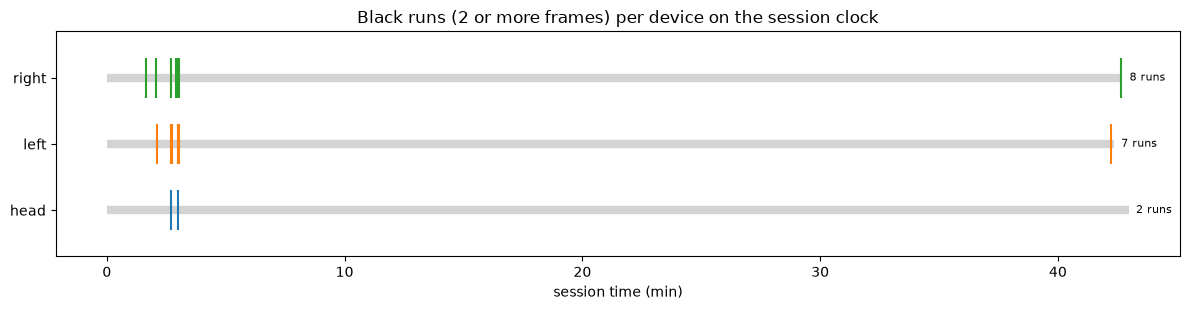

In [15]:
try:
    fig, ax = plt.subplots(figsize=(12, 3.2))
    for k, d in enumerate(DEVICES):
        s0 = (CF[(d, 1)]["offset_us"] - session_zero) / 60e6
        s1 = (CF[(d, nrank)]["offset_us"] + CF[(d, nrank)]["n_rows"] * FRAME_US - session_zero) / 60e6
        ax.hlines(k, s0, s1, color="lightgrey", lw=6)
        sub = BLACK[BLACK["device"] == d]
        mid = (sub["start_s"] + sub["end_s"]) / 2 / 60
        ax.vlines(mid, k - 0.3, k + 0.3, color=colors[d], lw=1.5)
        ax.text(s1 + 0.3, k, str(len(sub)) + " runs", va="center", fontsize=8)
    ax.set_yticks(range(len(DEVICES)))
    ax.set_yticklabels(DEVICES)
    ax.set_ylim(-0.7, len(DEVICES) - 0.3)
    ax.set_xlabel("session time (min)")
    ax.set_title("Black runs (2 or more frames) per device on the session clock")
    fig.tight_layout()
    fig.savefig(out_path("04_black_runs.png"), dpi=150)
    plt.show()
    plt.close(fig)
except Exception as e:
    print("step failed:", type(e).__name__, e)

## Summary and zip
Key numbers and test results go into one json file, then every 04_ file is put into share_04.zip.

In [16]:
try:
    def clean(o):
        if isinstance(o, (np.integer,)):
            return int(o)
        if isinstance(o, (np.floating,)):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, (dt.datetime, Path)):
            return str(o)
        if isinstance(o, pd.DataFrame):
            return None
        return str(o)


    summary = {
        "run_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "project_root": str(PROJECT_ROOT),
        "pairing": PAIR_CHECK,
        "max_abs_triplet_offset_ms": float(triplet[["left_minus_head_ms", "right_minus_head_ms"]].abs().to_numpy().max()),
        "triplet_fits": triplet_fits,
        "session_fit": {d: {k: v for k, v in SESS[d].items() if k != "bins"} for d in DEVICES},
        "session_differences": SESS_DIFF,
        "black_runs": {"n_runs": int(len(BLACK)), "overlap": BLACK_OVERLAP},
        "left0020_missing": {k: v for k, v in MISSING.items() if k != "indices"},
        "hevc_encoder_string": HEVC,
        "time_anchor": {"root_dur_s": TIME["root_dur_s"], "root_start_utc": TIME["root_start"].isoformat(),
                        "tag_minus_name_s": TIME["diff_s"], "slack_s": {d: TIME["dev"][d]["slack_s"] for d in DEVICES}},
        "tests": hyp.to_dict(orient="records"),
    }
    out_path("04_summary.json").write_text(json.dumps(summary, indent=2, default=clean), encoding="utf-8")

    zip_path = out_path("share_04.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        n_files = 0
        for p in sorted(REPORTS.glob("04_*")):
            if p.suffix.lower() in {".png", ".csv", ".json", ".txt"}:
                zf.write(p, arcname=p.name)
                n_files += 1

    print("summary")
    print("  triplets:", PAIR_CHECK["n_triplets"], "| one to one:", PAIR_CHECK["one_to_one"])
    print("  max triplet offset: %.2f ms" % summary["max_abs_triplet_offset_ms"])
    for d in DEVICES:
        print("  %s rate: %.6f Hz (%.1f ppm)" % (d, SESS[d]["rate_hz"], SESS[d]["rate_ppm_from_30"]))
    print("  black runs:", len(BLACK), "| overlap between devices:", "yes" if BLACK_OVERLAP["any"] else "no")
    print("  left 0020 missing frames:", MISSING.get("missing"))
    print("  encoder string in bitstream:", HEVC["names"] if HEVC["found"] else "none", "| in tags:", HEVC["tag_names"] or "none")
    print("  tests:", hyp["result"].value_counts().to_dict())
    print("zip:", zip_path, "with", n_files, "files")
except Exception as e:
    print("step failed:", type(e).__name__, e)

summary
  triplets: 15 | one to one: True
  max triplet offset: 66.31 ms
  head rate: 29.999942 Hz (-1.9 ppm)
  left rate: 29.999550 Hz (-15.0 ppm)
  right rate: 29.999005 Hz (-33.2 ppm)
  black runs: 17 | overlap between devices: yes
  left 0020 missing frames: 38
  encoder string in bitstream: none | in tags: ['lavf']
  tests: {'PASS': 5, 'INFO': 4, 'FLAG': 1}
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_04.zip with 15 files
